# Diabetes Outcome Classification (Problem Statement 8)
Predict whether a patient has diabetes (Outcome = 1) or not (Outcome = 0)
from 8 health measurements, and compare four classification algorithms.

Dataset: Pima Indians Diabetes Database (National Institute of Diabetes and
Digestive and Kidney Diseases), via Kaggle / UCI:
https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

## 1. Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
df = pd.read_csv("diabetes.csv")
print("Shape:", df.shape)
print(df.head())
print(df.describe().round(2))

Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
count       768.00   768.00         768.00         768.00   768.00  768.00   
mean          3.85   120.89          69.11          20.54    79.80   31.99   
std           3.37    31.97          19.36          1

## 3. Data cleaning

In [3]:
# 3a. Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# 3b. Hidden missing values: a value of 0 is medically impossible for these
# columns, so 0 really means "not recorded". Replace with NaN.
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_as_missing] == 0).sum()
print("Zeros that are really missing values:\n", zero_counts)
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

Duplicate rows: 0
Zeros that are really missing values:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


## 4. Exploratory data analysis (EDA)

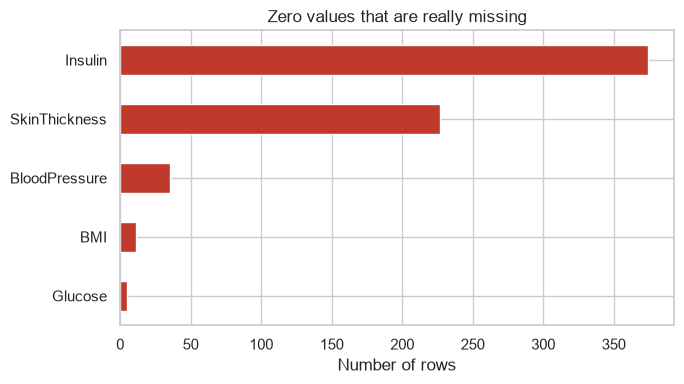

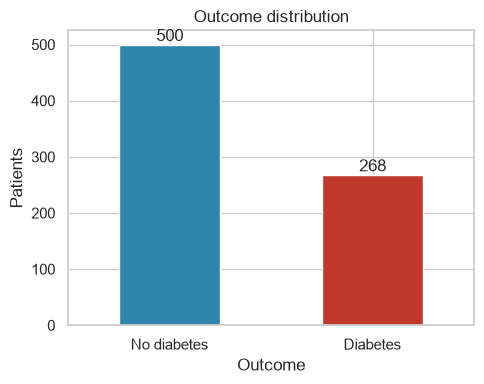

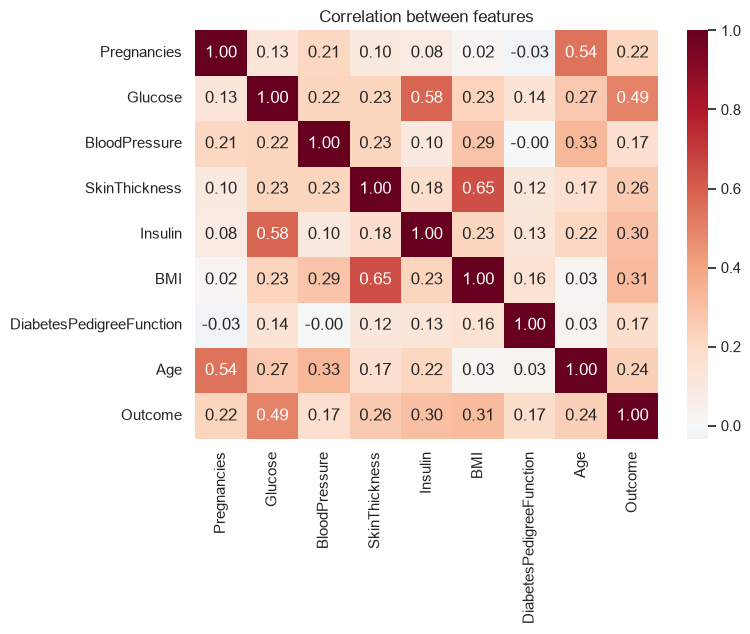

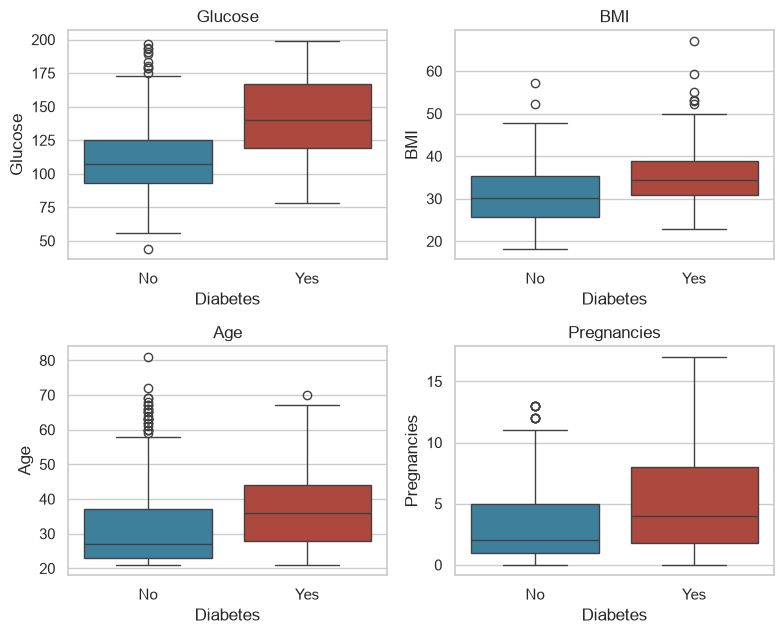

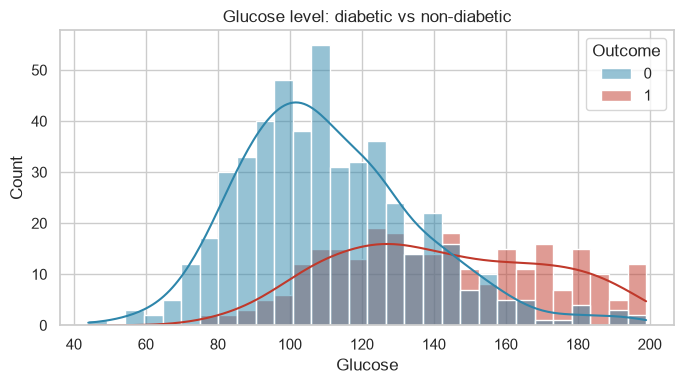

In [4]:
# Chart 1 - Hidden missing values per column
plt.figure(figsize=(7, 4))
zero_counts.sort_values().plot(kind="barh", color="#c0392b")
plt.title("Zero values that are really missing")
plt.xlabel("Number of rows")
plt.tight_layout()
plt.savefig("outputs/01_missing_values.png", dpi=150)
plt.show()

# Chart 2 - Class balance
plt.figure(figsize=(5, 4))
ax = df["Outcome"].map({0: "No diabetes", 1: "Diabetes"}).value_counts().plot(
    kind="bar", color=["#2e86ab", "#c0392b"], rot=0)
ax.bar_label(ax.containers[0])
plt.title("Outcome distribution")
plt.ylabel("Patients")
plt.tight_layout()
plt.savefig("outputs/02_class_balance.png", dpi=150)
plt.show()

# Chart 3 - Correlation heatmap
plt.figure(figsize=(8, 6.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation between features")
plt.tight_layout()
plt.savefig("outputs/03_correlation.png", dpi=150)
plt.show()

# Chart 4 - Key features by outcome
fig, axes = plt.subplots(2, 2, figsize=(8, 6.5))
for ax, col in zip(axes.flat, ["Glucose", "BMI", "Age", "Pregnancies"]):
    sns.boxplot(data=df, x="Outcome", y=col, ax=ax,
                hue="Outcome", palette=["#2e86ab", "#c0392b"], legend=False)
    ax.set_xticks([0, 1], ["No", "Yes"])
    ax.set_xlabel("Diabetes")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("outputs/04_features_by_outcome.png", dpi=150)
plt.show()

# Chart 5 - Glucose distribution by outcome
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Glucose", hue="Outcome", kde=True, bins=30,
             palette=["#2e86ab", "#c0392b"])
plt.title("Glucose level: diabetic vs non-diabetic")
plt.tight_layout()
plt.savefig("outputs/05_glucose_distribution.png", dpi=150)
plt.show()

## 5. Train-test split (stratified so both sets keep the 65/35 class ratio)

In [5]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (614, 8) Test: (154, 8)


## 6. Models

In [6]:
# Each model is a Pipeline: median imputation + scaling are learned from the
# training data only, which avoids data leakage into the test set.
def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

# class_weight="balanced" gives the minority class (diabetes) more weight, so
# the models miss fewer diabetic patients (higher recall). KNN has no such option.
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN (k=11)": KNeighborsClassifier(n_neighbors=11),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6,
                                            class_weight="balanced",
                                            random_state=RANDOM_STATE),
}

## 7. Train and evaluate

                     CV F1  Test Accuracy  Precision  Recall  F1-score
Model                                                                 
Logistic Regression  0.672          0.734      0.603   0.704     0.650
KNN (k=11)           0.611          0.734      0.633   0.574     0.602
Decision Tree        0.637          0.708      0.556   0.833     0.667
Random Forest        0.697          0.721      0.580   0.741     0.650


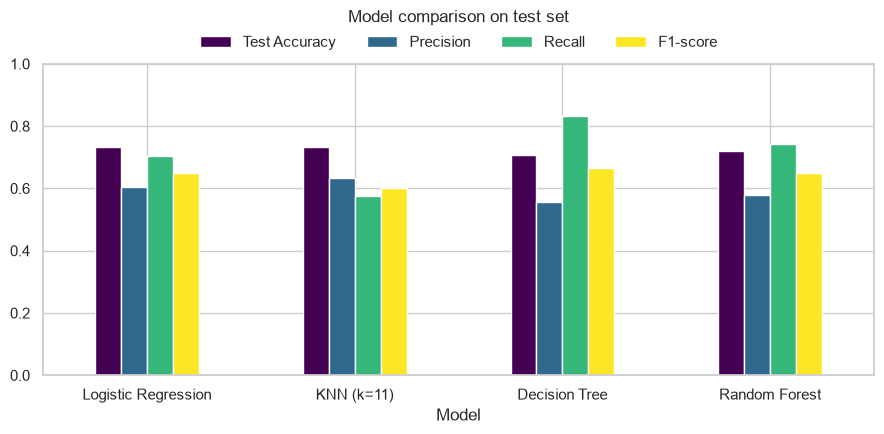

In [7]:
# 5-fold cross-validation on the training set gives a stable score for choosing
# the model; the held-out test set is used once for the final check.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
fitted = {}
for name, model in models.items():
    pipe = make_pipeline(model)
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        "Model": name,
        "CV F1": cv_f1,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results = pd.DataFrame(results).set_index("Model").round(3)
print(results)
results.to_csv("outputs/model_comparison.csv")

# Chart 6 - Model comparison
results[["Test Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(9, 4.5), rot=0, colormap="viridis")
plt.title("Model comparison on test set", pad=30)
plt.ylim(0, 1)
plt.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig("outputs/06_model_comparison.png", dpi=150)
plt.show()

## 8. Best model: confusion matrix and report

Best model (by cross-validated F1): Random Forest
              precision    recall  f1-score   support

 No diabetes       0.84      0.71      0.77       100
    Diabetes       0.58      0.74      0.65        54

    accuracy                           0.72       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.72      0.73       154



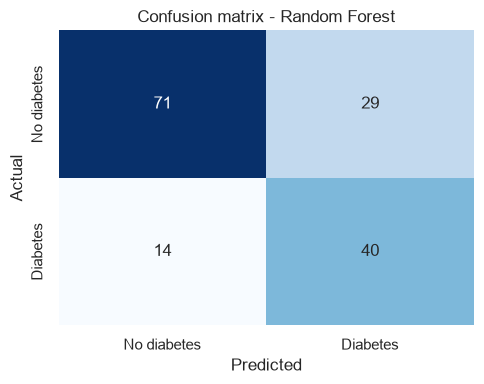

In [8]:
best_name = results["CV F1"].idxmax()
best = fitted[best_name]
best_pred = best.predict(X_test)
print("Best model (by cross-validated F1):", best_name)
print(classification_report(y_test, best_pred, target_names=["No diabetes", "Diabetes"]))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No diabetes", "Diabetes"],
            yticklabels=["No diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.savefig("outputs/07_confusion_matrix.png", dpi=150)
plt.show()
pd.DataFrame(cm, index=["Actual 0", "Actual 1"],
             columns=["Pred 0", "Pred 1"]).to_csv("outputs/confusion_matrix.csv")

## 9. Feature importance (Random Forest)

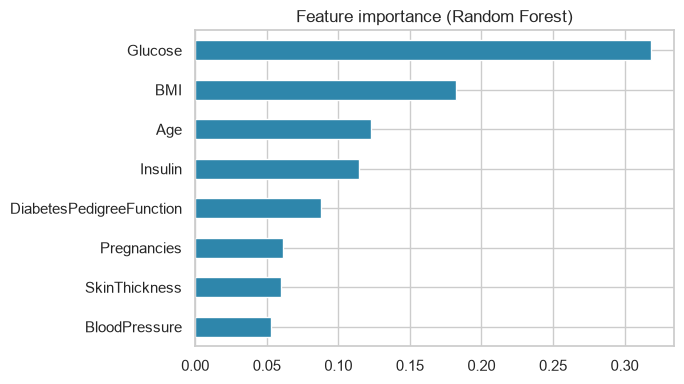

In [9]:
rf = fitted["Random Forest"].named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.round(3).to_csv("outputs/feature_importance.csv")
plt.figure(figsize=(7, 4))
importance.plot(kind="barh", color="#2e86ab")
plt.title("Feature importance (Random Forest)")
plt.tight_layout()
plt.savefig("outputs/08_feature_importance.png", dpi=150)
plt.show()

## 10. Demo: predict for new patients

In [10]:
new_patients = pd.DataFrame([
    {"Pregnancies": 1, "Glucose": 95, "BloodPressure": 70, "SkinThickness": 25,
     "Insulin": 80, "BMI": 23.5, "DiabetesPedigreeFunction": 0.30, "Age": 25},
    {"Pregnancies": 6, "Glucose": 168, "BloodPressure": 78, "SkinThickness": 35,
     "Insulin": 200, "BMI": 38.0, "DiabetesPedigreeFunction": 0.85, "Age": 50},
])
probs = best.predict_proba(new_patients)[:, 1]
for i, p in enumerate(probs, 1):
    label = "Diabetes" if p >= 0.5 else "No diabetes"
    print(f"Patient {i}: {label} (probability of diabetes = {p:.2f})")

Patient 1: No diabetes (probability of diabetes = 0.02)
Patient 2: Diabetes (probability of diabetes = 0.89)
